# **ResNet18 with CIFAR-10 — 학습/추론/시각화**

## 학습 목표
- Residual Connection(잔차 연결)의 구조와 원리를 이해하고, ResNet-18 모델을 CIFAR-10 이미지 분류 작업에 맞게 구현 및 최적화할 수 있도록 실습합니다.
- 데이터 전처리부터 모델 학습, 성능 평가, 그리고 Class Activation Map(CAM) 등을 활용한 추론 결과 시각화까지의 ResNet 파이프라인 전 과정을 익힙니다.

---

### 구성 개요
1. **CIFAR-10 로드** + 입력 이미지 크기 확인
2. **ResNet18(CIFAR-friendly)** 구성
3. **학습(Training)** + 체크포인트 저장/재개(있으면 +10 epoch, 없으면 20 epoch)
4. **추론(Inference)** + 예측/신뢰도 확인
5. **Confusion Matrix / 클래스별 정확도 / 오분류 샘플** 분석
6. **Activation Map** 시각화 (layer1 vs layer4 비교)
7. **Conv Kernel** 시각화 (초기/중간 레이어)
8. **Grad-CAM** 시각화 (Top-K 정분류 + Top-K 오분류: 원본과 Overlay 함께)
9. (추가 실습) **Receptive Field** 근사 계산 + 의미 설명
10. (추가 실습) **Embedding(t-SNE)** 시각화
11. (추가 실습) **ONNX Export + 모델 구조 출력** (Netron 비교용)

> 권장 실행: 위에서 아래로 순차 실행


---
## 0) Setup (환경 준비)
- **목적:** 실습에 필요한 패키지를 로드하고, 디바이스를 출력합니다.
- **관찰 포인트**
  - 실습에 필요한 유틸 패키지(`torch`, `torchvision`, `matplotlib`, `onnx` 등) 준비
  - GPU 사용 여부(`cuda`)와 제품명 확인

In [1]:
import importlib.util
import subprocess
import sys

def ensure_package(pkg_name: str, import_name=None):
    """
    패키지 설치 여부를 확인하고, 설치되어 있지 않으면 설치합니다.
    """
    name = import_name or pkg_name
    # 패키지가 설치되어 있는지 확인
    if importlib.util.find_spec(name) is None:
        print(f"[install] {pkg_name} 라이브러리를 설치 중입니다... (import name: {name})")
        try:
            # -q 옵션을 추가하여 설치 과정을 간결하게 유지할 수 있습니다.
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pkg_name])
            print(f"[success] {pkg_name} 설치 완료.")
        except subprocess.CalledProcessError as e:
            print(f"[error] {pkg_name} 설치 실패: {e}")
    else:
        print(f"[ok] {pkg_name} 이미 설치되어 있습니다.")

# 설치가 필요한 패키지 리스트 (패키지명, 임포트명)
# 임포트명이 패키지명과 다른 경우 튜플로 지정합니다.
packages = [
    ("torch", "torch"),
    ("torchvision", "torchvision"),
    ("matplotlib", "matplotlib"),
    ("onnx", "onnx"),
]

# 루프를 돌며 확인 및 설치
for pkg, imp in packages:
    ensure_package(pkg, imp)

[ok] torch 이미 설치되어 있습니다.
[ok] torchvision 이미 설치되어 있습니다.
[ok] matplotlib 이미 설치되어 있습니다.
[ok] onnx 이미 설치되어 있습니다.


In [3]:
import os  # path/환경 확인
import random  # seed 고정
import time  # epoch 시간 측정
import numpy as np  # 수치 계산
import torch  # PyTorch 본체
import torch.nn as nn  # 모델 레이어
import torch.nn.functional as F  # softmax 등 함수
from torch.utils.data import DataLoader  # 데이터 로더
import torchvision  # vision dataset/util
import torchvision.transforms as T  # transform
import torchvision.models as models  # resnet18
import matplotlib.pyplot as plt  # 시각화

print('torch:', torch.__version__)  # torch 버전 출력
print('torchvision:', torchvision.__version__)  # torchvision 버전 출력
print('cuda available:', torch.cuda.is_available())  # GPU 사용 가능 여부
if torch.cuda.is_available():
    print('gpu:', torch.cuda.get_device_name(0))  # GPU 이름 출력

try:
    get_ipython().system('nvidia-smi -L')  # GPU 목록 확인(가능한 경우)
except Exception as e:
    print('nvidia-smi not available:', e)  # nvidia-smi가 없는 환경이면 무시

def seed_everything(seed: int = 42):
    random.seed(seed)  # python random seed
    np.random.seed(seed)  # numpy seed
    torch.manual_seed(seed)  # torch CPU seed
    torch.cuda.manual_seed_all(seed)  # torch GPU seed
    torch.backends.cudnn.deterministic = False  # 성능 우선(완전 재현성 X)
    torch.backends.cudnn.benchmark = True  # 입력 크기 고정이면 속도 향상

seed_everything(42)  # seed 고정(실험 재현성)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # 실행 디바이스 선택
device  # 디바이스 출력


torch: 2.5.1
torchvision: 0.20.1+cpu
cuda available: True
gpu: Tesla T4
GPU 0: Tesla T4 (UUID: GPU-0924a0f4-61c3-54bf-c663-98394f6172ba)


device(type='cuda')

In [4]:
# import torchvision.transforms as T
# CIFAR-10에서 널리 쓰는 normalize 값  - 이건 그냥 갖다 쓰면 됨
CIFAR10_MEAN = (0.4914, 0.4822, 0.4465)  # 채널별 평균(R,G,B)
CIFAR10_STD  = (0.2023, 0.1994, 0.2010)  # 채널별 표준편차(R,G,B)

train_tfms = T.Compose([
    T.RandomCrop(32,padding=4),
    T.RandomHorizontalFlip(),
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

test_tfms = T.Compose([
    T.ToTensor(),
    T.Normalize(CIFAR10_MEAN, CIFAR10_STD)
])

data_root = './data'
train_set = torchvision.datasets.CIFAR10(root=data_root,train=True,download=True,transform=train_tfms)
test_set = torchvision.datasets.CIFAR10(root=data_root,train=False,download=True,transform=train_tfms)

Files already downloaded and verified
Files already downloaded and verified


In [7]:
classes_names = train_set.classes
print(classes_names)

['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [9]:
num_classes = len(classes_names)
print(num_classes)

10


In [25]:
x0,y0 = train_set[0]
print(f"Sample image tensot shape {x0.shape}")

Sample image tensot shape torch.Size([3, 32, 32])


In [26]:
batch_size = 256
num_workers = min(8, os.cpu_count() or 2) # dataloader worker 수 (환경에 맞게)

In [27]:
train_loader = torch.utils.data.DataLoader(dataset=train_set,batch_size=batch_size,shuffle=True,num_workers=num_workers,pin_memory=True)
test_loader = torch.utils.data.DataLoader(dataset=test_set,batch_size=batch_size,shuffle=False,num_workers=num_workers,pin_memory=True)

print(f"Total batch size (train : {len(train_loader)}, test: {len(test_loader)})")

Total batch size (train : 196, test: 40)


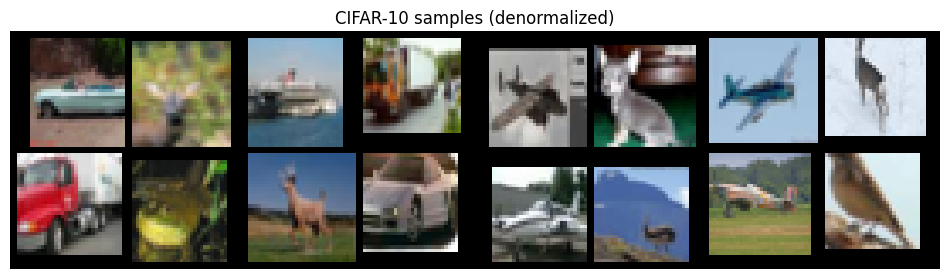

labels: ['automobile', 'deer', 'ship', 'truck', 'airplane', 'dog', 'airplane', 'deer', 'truck', 'frog', 'deer', 'automobile', 'airplane', 'bird', 'airplane', 'bird']


In [29]:
# x 의 shape은 B,C,H,W
def denorm(x):
    mean = torch.tensor(CIFAR10_MEAN).view(1,3,1,1)
    std = torch.tensor(CIFAR10_STD).view(1,3,1,1)
    return x * std + mean

images, labels = next(iter(train_loader))
images_dn = denorm(images[:16]).clamp(0,1)

grid = torchvision.utils.make_grid(images_dn,nrow=8)
plt.figure(figsize=(12,4))
plt.imshow(grid.permute(1,2,0))  # CHW -> HWC 로 변환 후 표시
plt.axis('off')
plt.title('CIFAR-10 samples (denormalized)')
plt.show()

print('labels:', [classes_names[int(x)] for x in labels[:16]])  # 라벨 이름 출력


In [36]:
def build_resnet18_for_cifar10(num_classes:int = 10):
    model = torchvision.models.resnet18(weights=None)
    model.conv1 = torch.nn.Conv2d(in_channels=3,out_channels=64,kernel_size=3,stride=1,padding=1,bias=False)
    model.maxpool = torch.nn.Identity() # 이미지가 작아서 identity로 만든다.T_destination
    model.fc = nn.Linear(model.fc.in_features,num_classes)
    return model

model = build_resnet18_for_cifar10(10).to(device)

In [37]:
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): Identity()
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), p

In [38]:
num_params = sum(p.numel() for p in model.parameters())
print(f"parameter numbers : {num_params}")

parameter numbers : 11173962


---
## 3) 학습 유틸리티
- **목적:** 학습/평가 루프를 재사용 가능하게 만들어 실험을 단순화합니다.
- **관찰 포인트**
  - `model.train()` vs `model.eval()` 차이
  - AMP(Automatic Mixed Precision) 사용
     - 계산이 복잡한 곳은 FP32를 쓰고, 단순한 곳은 FP16을 섞어서 사용
     - GradScaler의 역할: FP16을 쓰면 기울기(Gradient) 값이 너무 작아져서 사라질 위험이 있음 (언더플로우)
        - Scaling: 손실(Loss) 값에 아주 큰 값을 곱해 기울기를 크게 키움
        - Backprop: 커진 상태로 역전파를 수행하여 값이 사라지지 않게 보호
        - Unscaling: 업데이트 직전에 다시 원래 비율로 줄여서 가중치에 반영

In [39]:
from dataclasses import dataclass
@dataclass
class TrainConfig:
    base_epochs_if_new: int = 20 # 처음 실험 시 epoch 수
    extra_epochs_if_resume: int = 10 # 체크 포인트 존재 시 추가 실험 epoch 수
    lr: float = 0.1 # learning rate
    weight_decay:float = 5e-4 # L2 정규화
    momentum:float = 0.9 # SGD momentum
    label_smoothing:float = 0.0

cfg = TrainConfig()

In [40]:
def accuracy_top1(logits, targets):
    preds = logits.argmax(dim=1) # 가장큰 logit의 클래스 선택, logits = [B,C], preds = [B]
    return (preds==targets).float().mead().item()

scaler = torch.amp.GradScaler(enabled=torch.cuda.is_available()) # AMP 용 scaler, 학습속도를 높이고 메모리 사용량을 줄임

In [41]:
print(scaler)

In [ ]:
# train - 1개의 epoch에 대한거
def train_one_epoch(model, loader, optimizer, criterion):
    model.train() # train mode로 변경 dropout/bn 동작 변경
    total_loss, total_acc = 0.0, 0.0 # 누적 loss/acc
    n = 0 # 샘플 수 누적
    t0 = time.time()

    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_non=True)
